# Feature Engineering

This notebook extracts time-domain and frequency-domain features from the processed windows of Notebook 03.

**Changes compared with the earlier feature set (`PVS_Feature_Datasets`)**

| Earlier feature set | Revised feature set | Reason |
|---|---|---|
| raw signals incl. gravity | noise-handled signals + raw signals kept only for the baseline (C0) | noise handling (Notebook 03) |
| magnetometer and temperature included | excluded | not caused by road roughness; act as trip/vehicle shortcuts (Notebook 02, 10.4) |
| mean, std, RMS, min, max, range | mean, std, RMS, **IQR**, peak, range, skewness, kurtosis, crest factor | IQR and peak are required by the proposal; skewness/kurtosis/crest describe impacts |
| FFT dominant frequency, energy, entropy | **Welch PSD**: band powers (absolute and relative), total power, dominant frequency, centroid, entropy | PSD required by the proposal; bands follow vehicle dynamics |
| no noise floor handling | **noise-profile spectral subtraction** | removes vehicle/engine vibration measured while stationary |
| stationary windows included | all windows stored, exclusions applied in Notebook 05 | thresholds can be varied in the sensitivity analysis |

**Frequency bands:** 0.5–3 Hz (body bounce), 3–8 Hz, 8–16 Hz (wheel hop), 16–30 Hz, 30–45 Hz (surface texture).

In [1]:
# Setup: mount Drive and import the shared Component 4 pipeline (MyDrive/PVS_Code/c4_pipeline.py)
import os, sys, importlib
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

CODE_DIR = os.path.join(os.environ.get('C4_DRIVE', '/content/drive/MyDrive'), 'PVS_Code')
assert os.path.exists(os.path.join(CODE_DIR, 'c4_pipeline.py')), \
    'Upload c4_pipeline.py to MyDrive/PVS_Code/ before running this notebook.'
sys.path.insert(0, CODE_DIR)
import c4_pipeline as c4
importlib.reload(c4)
c4.ensure_dirs()
c4.check_setup();

Mounted at /content/drive
Drive folder      : /content/drive/MyDrive
Synced PVS1 found : True
Processed folder  : /content/drive/MyDrive/PVS_Processed True
Feature folder    : /content/drive/MyDrive/PVS_Feature_Datasets_v2 True
Results folder    : /content/drive/MyDrive/PVS_Model_Results_v2 True


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
plt.rcParams['figure.dpi'] = 110
CL = c4.CLASSES
COLORS = {'good': 'tab:green', 'regular': 'goldenrod', 'bad': 'tab:red'}

In [3]:
A = pd.read_parquet(os.path.join(c4.PROCESSED_DIR, 'windows.parquet'))
print('Windows:', len(A), '| window length:', c4.win_len(), 'samples | bands:', c4.bands())

Windows: 10795 | window length: 200 samples | bands: [(0.5, 3), (3, 8), (8, 16), (16, 30), (30, 45)]


## 1. Vehicle noise profiles
For each trip, the median PSD over all stationary windows is the vibration recorded without road input. If a trip has fewer than three stationary windows, the median profile of the same vehicle's other trips is used.

Stationary windows per trip: {'PVS1': 60, 'PVS2': 25, 'PVS3': 46, 'PVS4': 27, 'PVS5': 26, 'PVS6': 23, 'PVS7': 33, 'PVS8': 31, 'PVS9': 19}


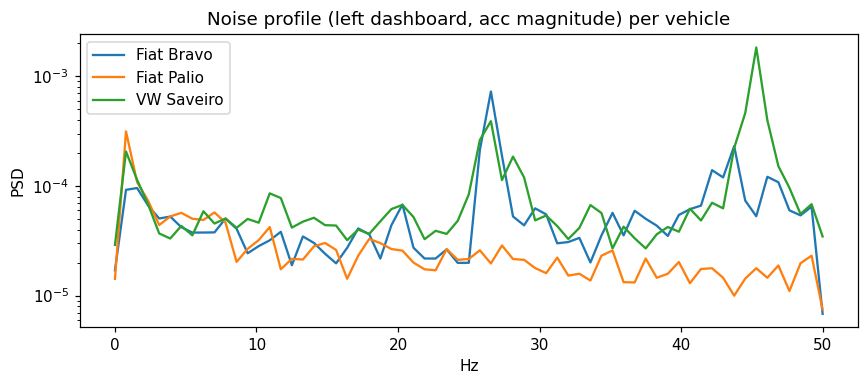

In [4]:
profiles, counts = {}, {}
for n in range(1, 10):
    S = c4.load_trip_signals(n)
    profiles[n] = c4.noise_profile(S['PROC'], S['STAT'])
    counts[f'PVS{n}'] = len(S['STAT'])
for n in range(1, 10):
    if profiles[n] is None:
        same = [profiles[m] for m in range(1, 10) if profiles[m] is not None and c4.PVS_META[m][0] == c4.PVS_META[n][0]]
        profiles[n] = np.median(same, axis=0) if same else None
        print(f'PVS{n}: no own stationary windows ->', 'vehicle profile used' if same else 'no subtraction')
print('Stationary windows per trip:', counts)

freqs = c4.welch(np.zeros((1, c4.win_len(), 1)))[0]
ci = c4.PROC_COLS.index('left_dashboard__acc_mag')
plt.figure(figsize=(8, 3.6))
for v in sorted(set(m[0] for m in c4.PVS_META.values())):
    ps = [profiles[n][:, ci] for n in range(1, 10) if c4.PVS_META[n][0] == v and profiles[n] is not None]
    if ps:
        plt.semilogy(freqs, np.median(ps, axis=0), label=v)
plt.xlabel('Hz'); plt.ylabel('PSD'); plt.title('Noise profile (left dashboard, acc magnitude) per vehicle')
plt.legend(); plt.tight_layout(); plt.savefig(os.path.join(c4.FEATURE_DIR, 'noise_profiles.png'), dpi=150); plt.show()

## 2. Feature extraction

In [5]:
import time
t0 = time.time()
F_RAW, F_PROC = [], []
for n in range(1, 10):
    S = c4.load_trip_signals(n)
    starts = A.loc[A.pvs == n, 'start'].values
    F_RAW.append(c4.compute_features(S['RAW'], c4.RAW_COLS, starts))
    F_PROC.append(c4.compute_features(S['PROC'], c4.PROC_COLS, starts, noise=profiles[n]))
    print(f'PVS{n}: {len(starts):,} windows ({time.time() - t0:.0f}s)')
F_RAW = pd.concat(F_RAW, ignore_index=True)
F_PROC = pd.concat(F_PROC, ignore_index=True)

A.to_parquet(os.path.join(c4.FEATURE_DIR, 'windows.parquet'), index=False)
F_RAW.to_parquet(os.path.join(c4.FEATURE_DIR, 'features_raw.parquet'), index=False)
F_PROC.to_parquet(os.path.join(c4.FEATURE_DIR, 'features_processed.parquet'), index=False)
print('raw features:', F_RAW.shape, '| processed features:', F_PROC.shape)

PVS1: 1,439 windows (7s)
PVS2: 1,245 windows (12s)
PVS3: 1,057 windows (16s)
PVS4: 1,323 windows (21s)
PVS5: 1,337 windows (26s)
PVS6: 961 windows (32s)
PVS7: 1,284 windows (40s)
PVS8: 1,235 windows (44s)
PVS9: 914 windows (48s)
raw features: (10795, 828) | processed features: (10795, 1380)


## 3. Feature inventory and quality check

In [6]:
inv = pd.DataFrame([c4.parse(c) for c in F_PROC.columns], columns=['domain', 'sensor', 'channel', 'statistic'])
print('Processed features per sensor and domain:')
display(inv.groupby(['sensor', 'domain']).size().unstack())
print('Statistics per channel:', sorted(inv.statistic.unique()))
q = pd.DataFrame({'NaN values': [int(F_RAW.isna().sum().sum()), int(F_PROC.isna().sum().sum())],
                  'columns': [F_RAW.shape[1], F_PROC.shape[1]]}, index=['raw', 'processed'])
display(q)

Processed features per sensor and domain:


domain,f,t
sensor,,
left_above_suspension,140,90
left_below_suspension,140,90
left_dashboard,140,90
right_above_suspension,140,90
right_below_suspension,140,90
right_dashboard,140,90


Statistics per channel: ['bpabs_0.5-3', 'bpabs_16-30', 'bpabs_3-8', 'bpabs_30-45', 'bpabs_8-16', 'bprel_0.5-3', 'bprel_16-30', 'bprel_3-8', 'bprel_30-45', 'bprel_8-16', 'centroid', 'crest', 'domfreq', 'entropy', 'iqr', 'kurt', 'logpow', 'mean', 'peak', 'range', 'rms', 'skew', 'std']


,NaN values,columns
raw,278,828
processed,70,1380


## 4. Evidence: class spectra before and after noise handling
Median PSD of moving, labelled windows per road class for the left dashboard sensor. Before: raw vertical axis. After: processed vertical acceleration with the vehicle noise profile removed. Clearer separation between the classes after processing indicates that the removed components were not road information.

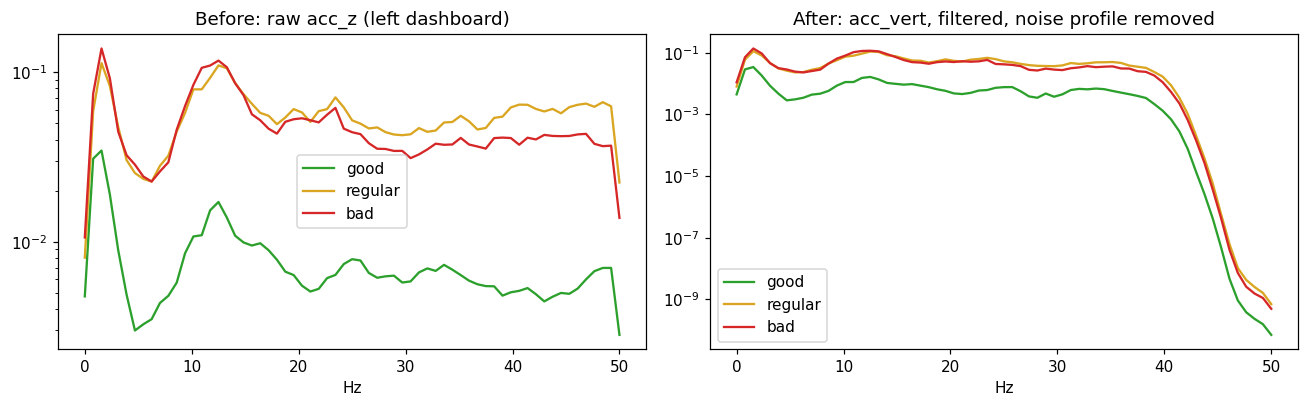

In [7]:
moving = (A.speed_mean >= c4.CFG['MIN_SPEED']) & (A.purity >= c4.CFG['MIN_PURITY']) & ~A.bump
ri, pi = c4.RAW_COLS.index('left_dashboard__acc_z'), c4.PROC_COLS.index('left_dashboard__acc_vert')
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
rng = np.random.default_rng(0)
for k, cls in enumerate(CL):
    Pr, Pp = [], []
    for n in range(1, 10):
        sel = A[(A.pvs == n) & moving & (A.maj_label == k)]
        if len(sel) == 0: continue
        st = rng.choice(sel.start.values, min(60, len(sel)), replace=False)
        S = c4.load_trip_signals(n)
        fr, p1 = c4.welch(c4.windows_of(S['RAW'][:, [ri]], st).astype(float))
        _, p2 = c4.welch(c4.windows_of(S['PROC'][:, [pi]], st).astype(float))
        if profiles[n] is not None:
            p2 = np.clip(p2 - profiles[n][None, :, [pi]], 1e-12, None)
        Pr.append(p1[..., 0]); Pp.append(p2[..., 0])
    if Pr:
        ax[0].semilogy(fr, np.median(np.vstack(Pr), 0), c=COLORS[cls], label=cls)
        ax[1].semilogy(fr, np.median(np.vstack(Pp), 0), c=COLORS[cls], label=cls)
ax[0].set_title('Before: raw acc_z (left dashboard)'); ax[1].set_title('After: acc_vert, filtered, noise profile removed')
for a in ax: a.set_xlabel('Hz'); a.legend()
plt.tight_layout(); plt.savefig(os.path.join(c4.FEATURE_DIR, 'class_spectra_before_after.png'), dpi=150); plt.show()

## 5. Summary
* Features were extracted for every window from 36 raw channels (baseline only) and 60 processed channels (6 sensors × 6 noise-handled axes + 4 orientation-invariant channels).
* Each channel provides 9 time-domain and 14 PSD-based features; two speed features are added in Notebook 05.
* Magnetometer and temperature features were removed.
* Outputs: `windows.parquet`, `features_raw.parquet`, `features_processed.parquet` in `MyDrive/PVS_Feature_Datasets_v2`.